In [ ]:
pip install pandas matplotlib seaborn statsmodels


READING CSV FILES
Current working directory: /content
Data folder: /content/Data
Year 2009 successfully read.
Year 2010 successfully read.
Year 2011 successfully read.
Year 2012 successfully read.
Year 2013 successfully read.
Year 2014 successfully read.
Year 2015 successfully read.
Year 2016 successfully read.
Year 2017 successfully read.
Year 2018 successfully read.
Year 2019 successfully read.
Year 2020 successfully read.
Year 2021 successfully read.
Year 2022 successfully read.
Year 2023 successfully read.
Year 2024 successfully read.

CHECKING IMPORTED DATA
Number of rows: 352

Available characteristics:
['Kenmerken werknemer', 'Totaal', 'Geslacht: mannen', 'Geslacht: vrouwen', 'Leeftijd: 0 tot 15 jaar', 'Leeftijd: 15 tot 20 jaar', 'Leeftijd: 20 tot 25 jaar', 'Leeftijd: 25 tot 30 jaar', 'Leeftijd: 30 tot 35 jaar', 'Leeftijd: 35 tot 40 jaar', 'Leeftijd: 40 tot 45 jaar', 'Leeftijd: 45 tot 50 jaar', 'Leeftijd: 50 tot 55 jaar', 'Leeftijd: 55 tot 60 jaar', 'Leeftijd: 60 tot 65 jaar', 

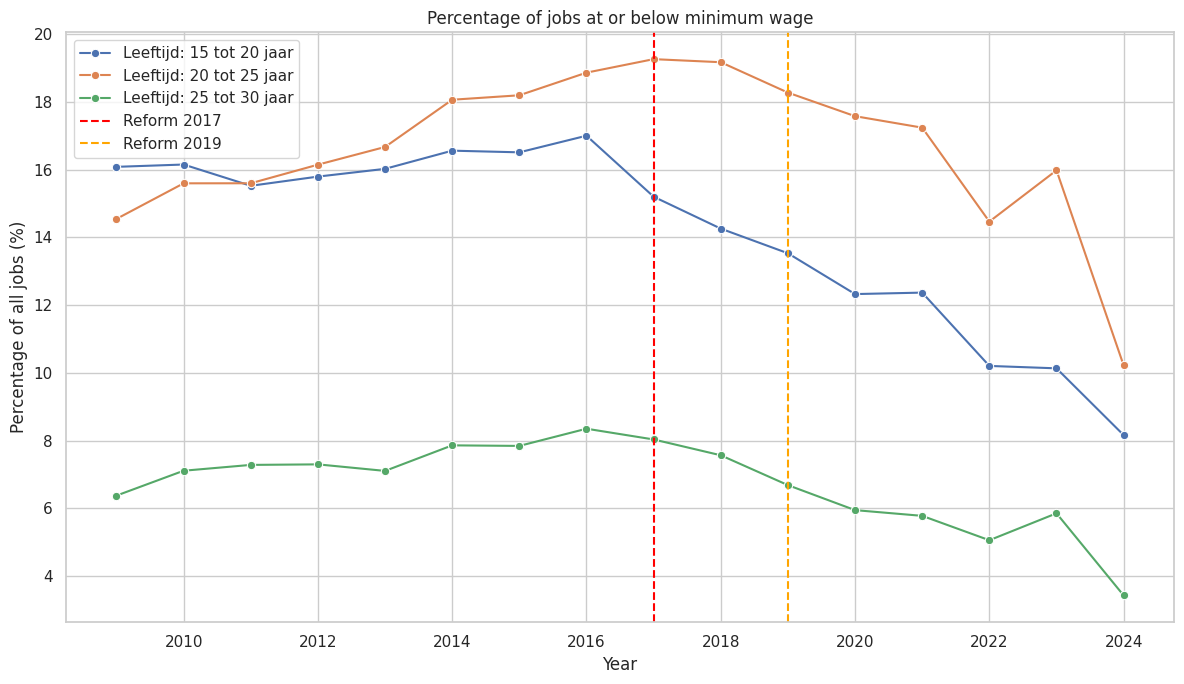

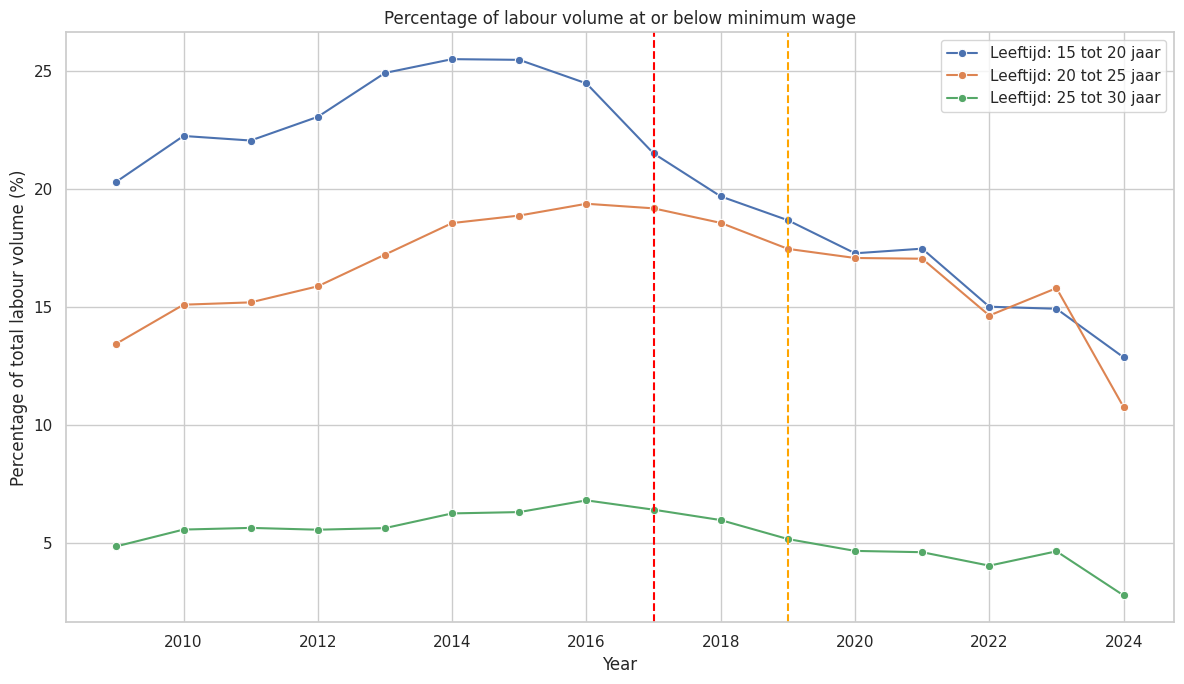

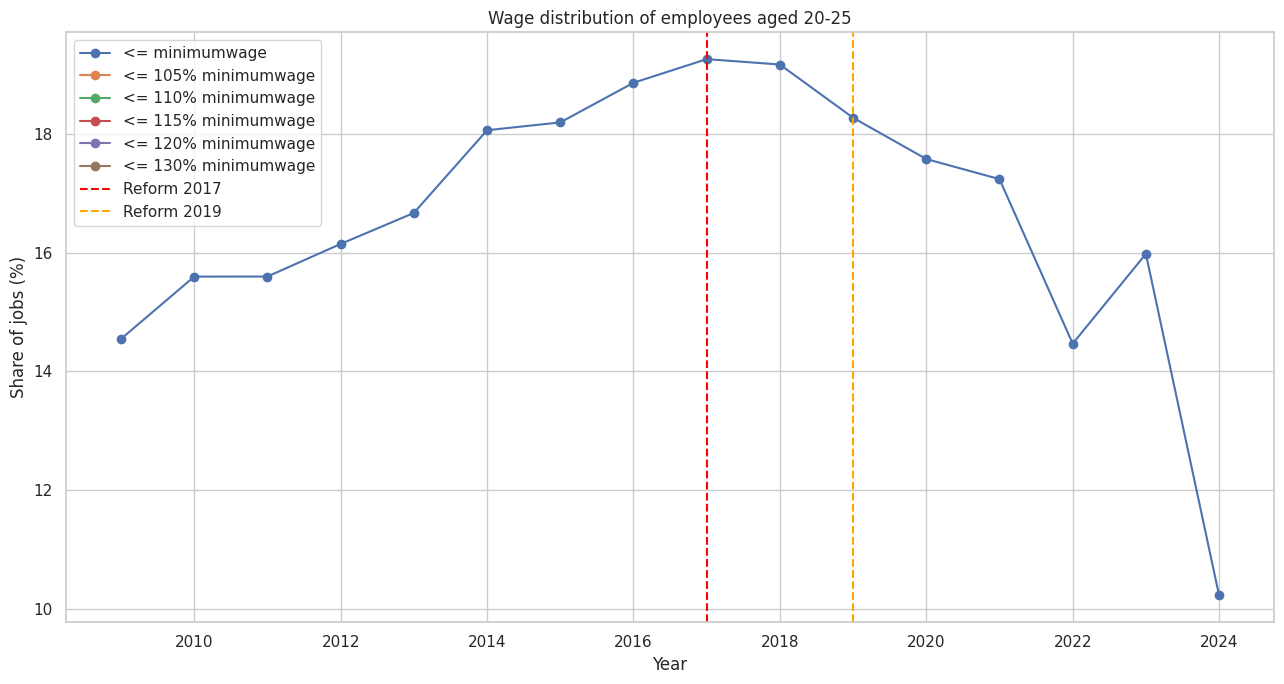


AVERAGE PERCENTAGE PER POLICY PERIOD
                     Age Policy_period   Year  Jobs_minimumwage  Volume_minimumwage  Jobs_105% minimumwage  Volume_105% minimumwage  Jobs_110% minimumwage  Volume_110% minimumwage  Jobs_115% minimumwage  Volume_115% minimumwage  Jobs_120% minimumwage  Volume_120% minimumwage  Jobs_130% minimumwage  Volume_130% minimumwage
Leeftijd: 15 tot 20 jaar Before reform 2012.5         16.205594           23.484616                    NaN                      NaN                    NaN                      NaN                    NaN                      NaN                    NaN                      NaN                    NaN                      NaN
Leeftijd: 15 tot 20 jaar    First step 2017.5         14.730154           20.577659                    NaN                      NaN                    NaN                      NaN                    NaN                      NaN                    NaN                      NaN                    NaN                

In [8]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


# Setting the data

DATA_MAP = Path("Data")
OUTPUT_MAP = Path("Results")
OUTPUT_MAP.mkdir(exist_ok=True)
YEARS = range(2009, 2025)

# Actual age group names from the CSV files

AGEGROUPS = [
    "Leeftijd: 15 tot 20 jaar",
    "Leeftijd: 20 tot 25 jaar",
    "Leeftijd: 25 tot 30 jaar",
]

# Reading the data

def make_number(value):
    """Convert Dutch numbers into numeric values."""

    if pd.isna(value):
        return float("nan")

    value = str(value).strip()

    if value in ["", "-", ".", "..."]:
        return float("nan")

    # Remove spaces and non-breaking spaces
    value = value.replace(" ", "")
    value = value.replace("\u00a0", "")

    # Dutch notation: 1.234,56
    if "," in value:
        value = value.replace(".", "")
        value = value.replace(",", ".")
    return pd.to_numeric(value, errors="coerce")


def read_year(file, year):
    """Read one CSV file with row 5 as headings."""

    try:
        df = pd.read_csv(
            file,
            sep=None,
            engine="python",
            skiprows=4,
            header=0,
            encoding="utf-8-sig",
            dtype=str
        )

    except UnicodeDecodeError:
        df = pd.read_csv(
            file,
            sep=None,
            engine="python",
            skiprows=4,
            header=0,
            encoding="cp1252",
            dtype=str
        )

    # Clean column names
    df.columns = [
        str(column).strip()
        for column in df.columns
    ]

    # Rename first column
    first_column = df.columns[0]

    df = df.rename(
        columns={first_column: "Characteristic"}
    )

    # Clean characteristic names
    df["Characteristic"] = (
        df["Characteristic"]
        .str.strip()
    )

    # Remove empty rows
    df = df.dropna(
        subset=["Characteristic"]
    )

    # Convert all numeric columns
    for column in df.columns:
        if column != "Characteristic":
            df[column] = df[column].apply(
                make_number
            )

    # Add year
    df["Year"] = year
    return df


# Combining CSV files

all_data = []

print("\nREADING CSV FILES")
print("Current working directory:", Path.cwd())
print("Data folder:", DATA_MAP.resolve())

for year in YEARS:

    file = DATA_MAP / f"{year}.csv"

    if not file.exists():
        print(f"File is missing: {file}")
        continue

    try:
        df = read_year(file, year)
        if df.empty:
            print(f"Warning: {year} contains no usable data.")
            continue
        all_data.append(df)
        print(f"Year {year} successfully read.")

    except Exception as mistake:
        print(f"Error reading {year}:")
        print(type(mistake).__name__, mistake)


if not all_data:
    raise ValueError(
        "No CSV files have been read successfully. "
        "Check the file paths and error messages."
    )


# Combine all years

data = pd.concat(
    all_data,
    ignore_index=True
)

# Save combined dataset

data.to_csv(
    OUTPUT_MAP / "combined_data.csv",
    index=False,
    encoding="utf-8-sig"
)

# Checking the imported data

print("\nCHECKING IMPORTED DATA")
print("Number of rows:", len(data))
print("\nAvailable characteristics:")
print(
    data["Characteristic"]
    .unique()
    .tolist()
)

print("\nAvailable columns:")
print(data.columns.tolist())


# Selecting the age groups

data_age = data[
    data["Characteristic"].isin(AGEGROUPS)
].copy()

if data_age.empty:
    print("\nAvailable characteristics:")
    print(
        data["Characteristic"]
        .unique()
        .tolist()
    )

    raise ValueError(
        "No age groups found. "
        "Check the age group names."
    )

print("\nAge groups successfully selected.")
print(
    data_age["Characteristic"]
    .value_counts()
)

# Calculating the percentages

# Wage thresholds:
# English label: actual Dutch column name

WAGE_LIMITS = {
    "minimumwage": "minimumloon",
    "105% minimumwage": "105% minimumloon",
    "110% minimumwage": "110% minimumloon",
    "115% minimumwage": "115% minimumloon",
    "120% minimumwage": "120% minimumloon",
    "130% minimumwage": "130% minimumloon",
}

results = []

for _, row in data_age.iterrows():
    result = {
        "Year": row["Year"],
        "Age": row["Characteristic"]
    }

    # Total number of jobs and labour volume

    total_jobs = row.get(
        "Banen|Totaal banen"
    )

    total_volume = row.get(
        "Arbeidsvolume|Totaal arbeidsvolume"
    )

    for limit, dutch_limit in WAGE_LIMITS.items():

        # Actual CSV column names

        jobs_column = (
            f"Banen|<= {dutch_limit}"
        )
        volume_column = (
            f"Arbeidsvolume|<= {dutch_limit}"
        )
        jobs = row.get(jobs_column)
        volume = row.get(volume_column)


        # Percentage of jobs

        if (
            pd.notna(total_jobs)
            and total_jobs != 0
            and pd.notna(jobs)
        ):
            result[f"Jobs_{limit}"] = (
                jobs / total_jobs * 100
            )
        else:
            result[f"Jobs_{limit}"] = float("nan")


        # percentage of labour volume

        if (
            pd.notna(total_volume)
            and total_volume != 0
            and pd.notna(volume)
        ):
            result[f"Volume_{limit}"] = (
                volume / total_volume * 100
            )
        else:
            result[f"Volume_{limit}"] = float("nan")
    results.append(result)


# Create analysis dataframe
analysis = pd.DataFrame(results)


# Adding the policy periods

analysis["Policy_period"] = pd.cut(
    analysis["Year"],
    bins=[2008, 2016, 2018, 2024],
    labels=[
        "Before reform",
        "First step",
        "Second step"
    ]
)


# Save yearly analysis

analysis.to_csv(
    OUTPUT_MAP / "analyse_per_jaar.csv",
    index=False,
    encoding="utf-8-sig"
)


# Calculating the average per policy period

averages = (
    analysis
    .groupby(
        ["Age", "Policy_period"],
        observed=True
    )
    .mean(numeric_only=True)
    .reset_index()
)

# Save averages

averages.to_csv(
    OUTPUT_MAP / "gemiddelden_per_periode.csv",
    index=False,
    encoding="utf-8-sig"
)


# Creating the graphs

sns.set_theme(style="whitegrid")


# Graph 1: Share of jobs at or below minimum wage

plt.figure(figsize=(12, 7))

sns.lineplot(
    data=analysis,
    x="Year",
    y="Jobs_minimumwage",
    hue="Age",
    marker="o"

)

plt.axvline(
    2017,
    color="red",
    linestyle="--",
    label="Reform 2017"
)

plt.axvline(
    2019,
    color="orange",
    linestyle="--",
    label="Reform 2019"
)

plt.title(
    "Percentage of jobs at or below minimum wage"
)
plt.ylabel(
    "Percentage of all jobs (%)"
)
plt.xlabel("Year")
plt.legend()
plt.tight_layout()

plt.savefig(
    OUTPUT_MAP / "graph_jobs_minimumwage.png",
    dpi=300
)
plt.show()


# Graph 2: Share of labour volume at or below minimum wage
plt.figure(figsize=(12, 7))

sns.lineplot(
    data=analysis,
    x="Year",
    y="Volume_minimumwage",
    hue="Age",
    marker="o"
)

plt.axvline(
    2017,
    color="red",
    linestyle="--"
)

plt.axvline(
    2019,
    color="orange",
    linestyle="--"
)

plt.title(
    "Percentage of labour volume at or below minimum wage"
)
plt.ylabel(
    "Percentage of total labour volume (%)"
)
plt.xlabel("Year")
plt.legend()
plt.tight_layout()

plt.savefig(
    OUTPUT_MAP / "graph_labourvolume_minimumwage.png",
    dpi=300
)
plt.show()

# Graph 3: wage thresholds for 20-25 year old
jongeren = analysis[
    analysis["Age"] == "Leeftijd: 20 tot 25 jaar"
].copy()

plt.figure(figsize=(13, 7))

for limit in WAGE_LIMITS:
    column = f"Jobs_{limit}"
    plt.plot(
        jongeren["Year"],
        jongeren[column],
        marker="o",
        label=f"<= {limit}"
    )

plt.axvline(
    2017,
    color="red",
    linestyle="--",
    label="Reform 2017"
)

plt.axvline(
    2019,
    color="orange",
    linestyle="--",
    label="Reform 2019"
)

plt.title(
    "Wage distribution of employees aged 20-25"
)
plt.ylabel(
    "Share of jobs (%)"
)
plt.xlabel("Year")
plt.legend()
plt.tight_layout()
plt.savefig(

    OUTPUT_MAP / "graph_all_wage_limits.png",

    dpi=300
)
plt.show()


# Print results
print("\nAVERAGE PERCENTAGE PER POLICY PERIOD")
print(
    averages.to_string(index=False)
)
print("\nYEARLY ANALYSIS")
print(
    analysis.to_string(index=False)
)
print("\nAnalysis complete!")
print(
    f"Results saved in: {OUTPUT_MAP.resolve()}"
)
